<a href="https://colab.research.google.com/github/johnriskquant/math-for-ml-data-science-notes/blob/main/prob-stats/week-2-prob-dist-with-multiple-vars/simulating_dice_rolls.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Simulating die rolls with numpy**

Labbing out die rolls and analyzing the probabilities

In [4]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

**Let make a dice 🎲**

In [5]:
num_sides = 6
dice = np.array([i for i in range(1, num_sides+1)])
dice

array([1, 2, 3, 4, 5, 6])

Roll the dice

In [6]:
np.random.choice(dice)

np.int64(4)

In [7]:
num_rolls = 20
rolls = np.array([np.random.choice(dice) for _ in range(num_rolls)])
rolls

array([6, 5, 1, 6, 6, 1, 6, 4, 4, 5, 5, 2, 1, 5, 4, 6, 5, 6, 6, 2])

**Some quick stats**

In [8]:
mu = np.mean(rolls)
var = np.var(rolls)
print(f"mean of {num_rolls} rolls: {mu:.2f}\nvariance of {num_rolls}: {var:.2f}")

mean of 20 rolls: 4.30
variance of 20: 3.31


Lets check the distribution of the rolls by plotting a histogram of the NumPy array that holds the result of each throw. For this you will use the plotting library Seaborn, concretely the [sns.histplot](https://seaborn.pydata.org/generated/seaborn.histplot.html) function:



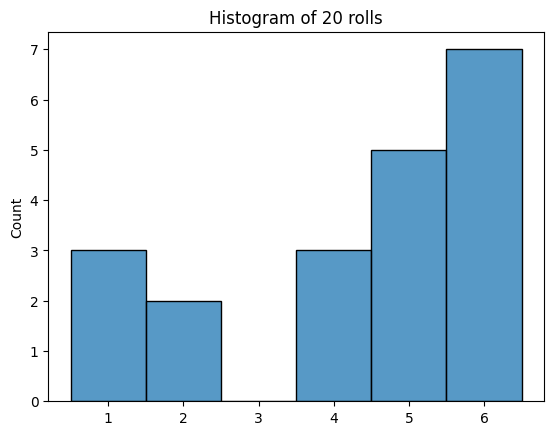

In [9]:
num_rolls_hist = sns.histplot(rolls, discrete=True)
num_rolls_hist.set(title=f"Histogram of {num_rolls} rolls")
plt.show()

Observe that we didn't get a uniform distribution like we expected (note: `np.random.choice` ~ $\text{Uniform}(a, b)$ when no prob distribution is specified) because our sample size is small. Lets simulate 20k rolls.

mean of 20000 rolls: 3.50
variance of 20000: 2.92


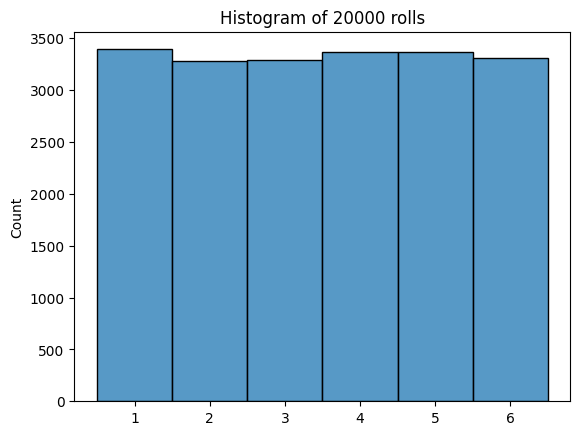

In [10]:
num_rolls = 20000
rolls = np.array([np.random.choice(dice) for i in range(num_rolls)])
print(f"mean of {num_rolls} rolls: {np.mean(rolls):.2f}\nvariance of {num_rolls}: {np.var(rolls):.2f}")
num_rolls_hist = sns.histplot(rolls, discrete=True)
num_rolls_hist.set(title=f"Histogram of {num_rolls} rolls")
plt.show()

**Simulating two die rolls**

Suppose we have two dice and we wanted to simulate the sum of the two die rolls, such that: $X_1 + X_2 = Y$ where $Y$ is the sum of each roll.

In [11]:
X1 = np.array([np.random.choice(dice) for _ in range(num_rolls)])
X2 = np.array([np.random.choice(dice) for _ in range(num_rolls)])
Y = X1 + X2

print(f"mean of X1:{np.mean(X1): 2f} \nvariance of X1: {np.var(X1):2f}")
print(f"mean of X2:{np.mean(X2): 2f} \nvariance of X2: {np.var(X2):2f}")
print(f"mean of Y:{np.mean(Y): 2f} \nvariance of Y: {np.var(Y):2f}")
print(f"covariance btw X1 and X2:\n{np.cov(X1,X2)}")

mean of X1: 3.477350 
variance of X1: 2.921587
mean of X2: 3.511050 
variance of X2: 2.903678
mean of Y: 6.988400 
variance of Y: 5.805965
covariance btw X1 and X2:
[[ 2.92173306 -0.0096502 ]
 [-0.0096502   2.90382309]]


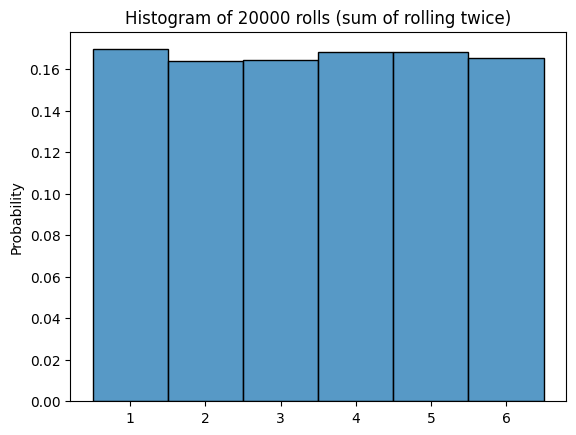

In [12]:
Y_hist = sns.histplot(rolls, stat = "probability", discrete=True)
Y_hist.set(title=f"Histogram of {num_rolls} rolls (sum of rolling twice)")
plt.show()

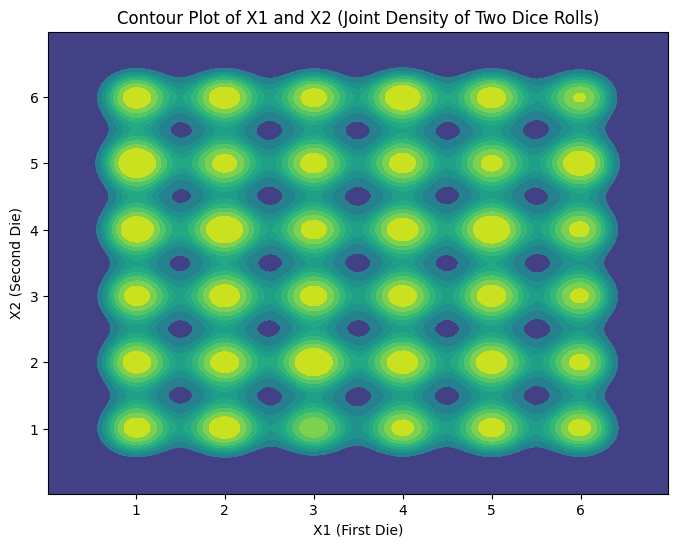

In [13]:
plt.figure(figsize=(8, 6))
contour_plot = sns.kdeplot(x=X1, y=X2, cmap="viridis", fill=True, thresh=0, levels=10)
contour_plot.set(title="Contour Plot of X1 and X2 (Joint Density of Two Dice Rolls)", xlabel="X1 (First Die)", ylabel="X2 (Second Die)")
plt.show()

**Using a loaded dice**

In [14]:
def load_dice(num_sides, loaded_side):
  probs = np.array([1/(num_sides+1) for _ in range(num_sides)])
  print(probs)
  probs[loaded_side-1] = 1 - sum(probs[:-1])

  if not np.isclose(sum(probs),1):
    print("All probs should add up to 1")
    return
  return probs

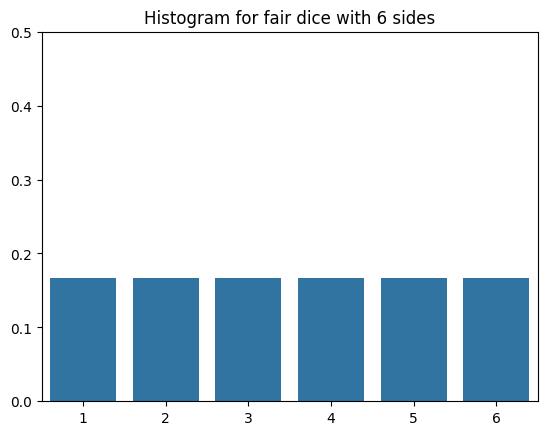

In [15]:
probs_fair_dice = np.array([1/num_sides]*num_sides)
fair_dice_sides = sns.barplot(x=dice, y=probs_fair_dice)
fair_dice_sides.set(title=f"Histogram for fair dice with {num_sides} sides")
fair_dice_sides.set_ylim(0,0.5)
plt.show()

[0.14285714 0.14285714 0.14285714 0.14285714 0.14285714 0.14285714]


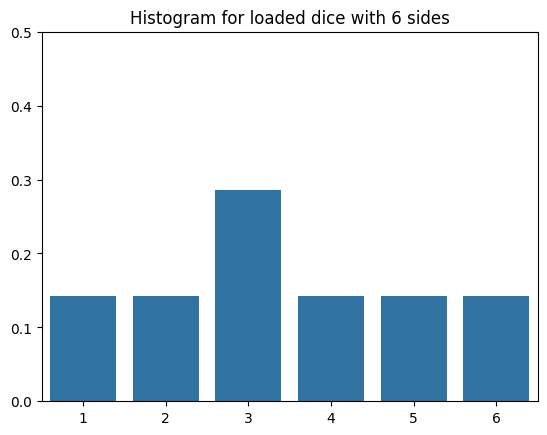

In [16]:
prob_loaded_dice = load_dice(num_sides, 3)
loaded_dice_sides = sns.barplot(x=dice, y=prob_loaded_dice)
loaded_dice_sides.set(title=f"Histogram for loaded dice with {num_sides} sides")
loaded_dice_sides.set_ylim(0,0.5)
plt.show()

mean of X1: 3.426850 
variance of X1: 2.539949
mean of X2: 3.413650 
variance of X2: 2.533244
mean of Y: 6.840500 
variance of Y: 5.058460
covariance btw X1 and X2:
[[ 2.54007608 -0.00736687]
 [-0.00736687  2.53337035]]


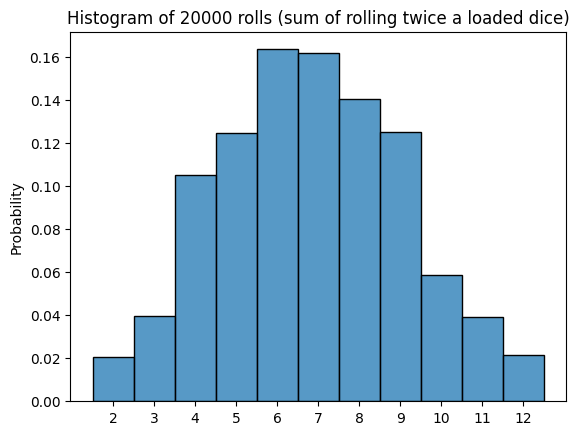

In [17]:
X1 = np.array([np.random.choice(dice, p=prob_loaded_dice) for _ in range(num_rolls)])
X2 = np.array([np.random.choice(dice, p=prob_loaded_dice) for _ in range(num_rolls)])
Y = X1 + X2

print(f"mean of X1:{np.mean(X1): 2f} \nvariance of X1: {np.var(X1):2f}")
print(f"mean of X2:{np.mean(X2): 2f} \nvariance of X2: {np.var(X2):2f}")
print(f"mean of Y:{np.mean(Y): 2f} \nvariance of Y: {np.var(Y):2f}")
print(f"covariance btw X1 and X2:\n{np.cov(X1,X2)}")
# Plot histogram
loaded_rolls_hist = sns.histplot(Y, stat = "probability", discrete=True)
loaded_rolls_hist.set(title=f"Histogram of {num_rolls} rolls (sum of rolling twice a loaded dice)")
loaded_rolls_hist.set_xticks(range(min(Y),max(Y)+1))
plt.show()

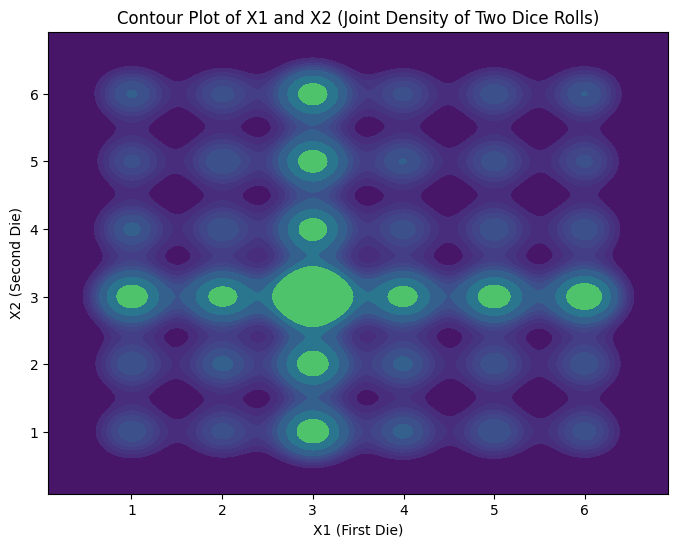

In [18]:
plt.figure(figsize=(8, 6))
contour_plot = sns.kdeplot(x=X1, y=X2, cmap="viridis", fill=True, thresh=0, levels=10)
contour_plot.set(title="Contour Plot of X1 and X2 (Joint Density of Two Dice Rolls)", xlabel="X1 (First Die)", ylabel="X2 (Second Die)")
plt.show()

**Dependent Rolls**

Lets simulate the scenario in which the second roll depends on the result of the first one. Say that you are playing a variant of the game you have played so far and you only roll the dice a second time if the result of the first roll is greater or equal to 4.

Before doing the simulations reflect on what might happen in this scenario. Some behavior you will probably see:

- 1 is now a possible result since if you get a 1 in the first roll you don't roll again
- 1, 2 and 3 now have a greater chance of showing up
- 4 is now not a possible result since you need to roll again if you get a 4 in the first roll

mean of X1: 3.486450 
variance of X1: 2.914816
mean of X2: 1.717250 
variance of X2: 4.445402
mean of Y: 5.203700 
variance of Y: 12.567706
covariance btw X1 and X2:
[[2.91496215 2.60387393]
 [2.60387393 4.44562472]]


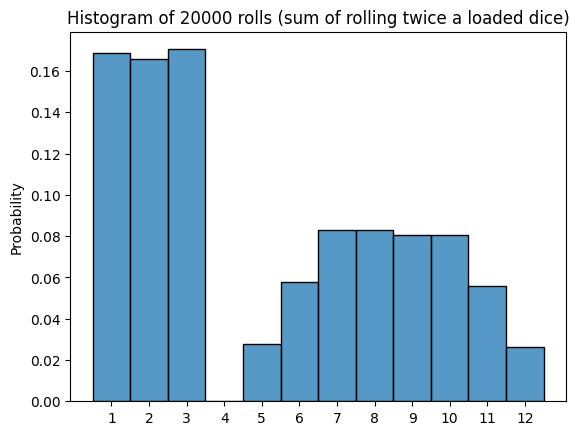

In [19]:
X1 = np.array([np.random.choice(dice) for _ in range(num_rolls)])
X2 = np.where(X1>=4, np.array([np.random.choice(dice) for _ in range(num_rolls)]),0)
Y = X1 + X2

print(f"mean of X1:{np.mean(X1): 2f} \nvariance of X1: {np.var(X1):2f}")
print(f"mean of X2:{np.mean(X2): 2f} \nvariance of X2: {np.var(X2):2f}")
print(f"mean of Y:{np.mean(Y): 2f} \nvariance of Y: {np.var(Y):2f}")
print(f"covariance btw X1 and X2:\n{np.cov(X1,X2)}")
dependent_rolls_hist = sns.histplot(Y, stat = "probability", discrete=True)
dependent_rolls_hist.set(title=f"Histogram of {num_rolls} rolls (sum of rolling twice a loaded dice)")
dependent_rolls_hist.set_xticks(range(min(Y),max(Y)+1))
plt.show()

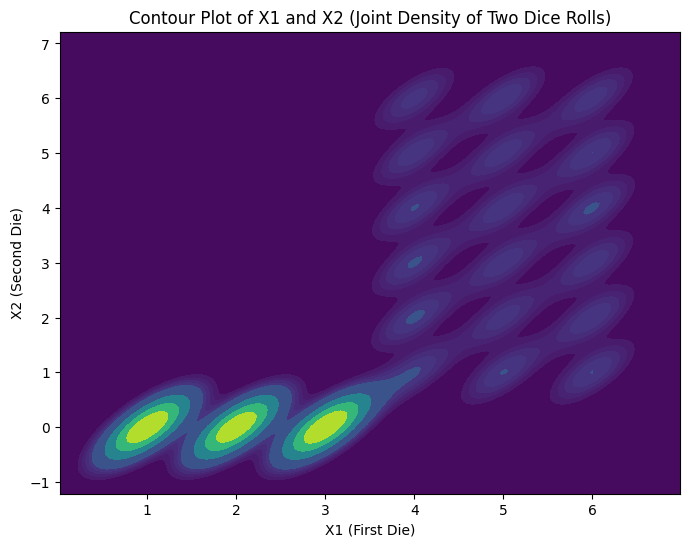

In [20]:
plt.figure(figsize=(8, 6))
contour_plot = sns.kdeplot(x=X1, y=X2, cmap="viridis", fill=True, thresh=0, levels=10)
contour_plot.set(title="Contour Plot of X1 and X2 (Joint Density of Two Dice Rolls)", xlabel="X1 (First Die)", ylabel="X2 (Second Die)")
plt.show()

In [21]:
# Initialize empty dictionaries to store our statistics for different number of die sides
mu_rolls = {}
var_rolls = {}
cov_rolls = {}

# Run the simulation for dice with 2 to 20 sides
num_simulations = 500
for sides in range(2, 21):
    # Simulate 500 rolls for two independent dice
    X1_sim = np.random.randint(1, sides + 1, size=num_simulations)
    X2_sim = np.random.randint(1, sides + 1, size=num_simulations)
    Y_sim = X1_sim + X2_sim

    # Calculate statistics
    mu_rolls[sides] = np.mean(Y_sim)
    var_rolls[sides] = np.var(Y_sim)
    cov_rolls[sides] = np.cov(X1_sim, X2_sim)[0, 1]

In [22]:
import pandas as pd

# Create the DataFrame by passing the list of dictionaries, transposing, and naming the columns
df_rolls = pd.DataFrame([mu_rolls, var_rolls, cov_rolls]).T
df_rolls.columns = ['mean', 'var', 'cov']

display(df_rolls)

,mean,var,cov
2,3.010,0.489900,-0.004866
3,3.992,1.335936,0.004393
4,5.040,2.486400,-0.050244
5,6.090,4.161900,0.093387
6,6.868,5.086576,-0.356569
7,8.096,8.186784,0.106309
8,9.076,11.038224,0.177010
9,10.056,12.356864,-0.466341
10,11.272,17.686016,0.334673
11,11.820,19.163600,-0.222381


### Why are the Mean and Variance Increasing?

As the number of sides ($n$) on your dice increases, the range of possible outcomes grows, which directly increases both the expected average sum and the spread (variance) of the results:

1. **Mean ($E[Y] = n + 1$):** Since the average roll of one $n$-sided die is $\frac{n+1}{2}$, the sum of two independent rolls scales linearly with $n$.
2. **Variance ($\text{Var}(Y) = \frac{n^2 - 1}{6}$):** Because a larger $n$ allows for vastly wider outcomes (e.g., a sum up to 40 instead of just 12), the variance grows quadratically.
3. **Covariance ($\approx 0$):** Since the two rolls are independent, their covariance remains flat near $0$ regardless of the number of sides.

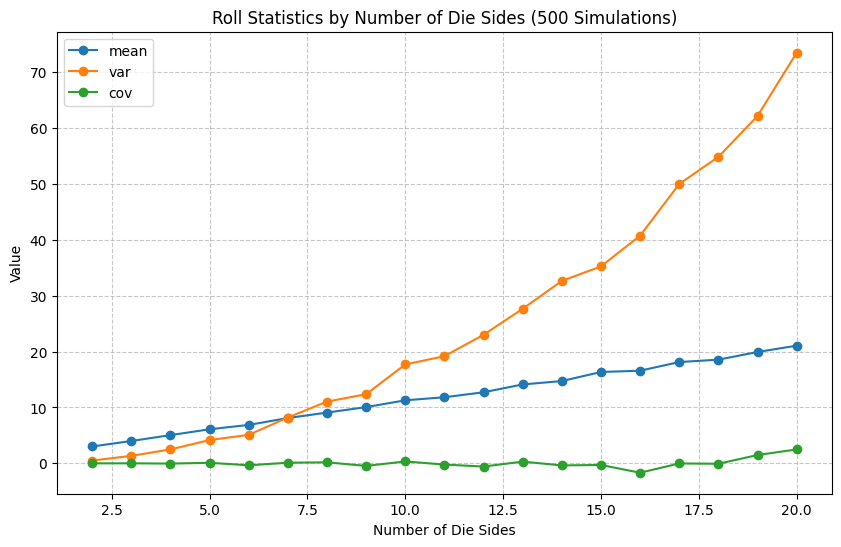

In [23]:
# Plotting the metrics over the number of die sides
ax = df_rolls.plot(figsize=(10, 6), marker='o')
ax.set_title("Roll Statistics by Number of Die Sides (500 Simulations)")
ax.set_xlabel("Number of Die Sides")
ax.set_ylabel("Value")
ax.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [24]:
# Initialize three completely independent dictionaries
mu_Y = {}
var_Y = {}
cov = {}

sim = 500
num_sides = 6
dice = np.arange(1, num_sides + 1)

for i in range(1, 7):
    # load_dice is already defined in your notebook
    dice_prob = load_dice(num_sides, i)
    X1 = np.array([np.random.choice(dice, p=dice_prob) for _ in range(sim)])
    X2 = np.array([np.random.choice(dice, p=dice_prob) for _ in range(sim)])
    Y = X1 + X2

    # These will now write to separate dictionaries
    mu_Y[i] = np.mean(Y)
    var_Y[i] = np.var(Y)
    cov[i] = np.cov(X1, X2)[0, 1]

# Create the corrected DataFrame
df_rolls_corrected = pd.DataFrame([mu_Y, var_Y, cov]).T
df_rolls_corrected.columns = ['mean', 'var', 'cov']
display(df_rolls_corrected)

[0.14285714 0.14285714 0.14285714 0.14285714 0.14285714 0.14285714]
[0.14285714 0.14285714 0.14285714 0.14285714 0.14285714 0.14285714]
[0.14285714 0.14285714 0.14285714 0.14285714 0.14285714 0.14285714]
[0.14285714 0.14285714 0.14285714 0.14285714 0.14285714 0.14285714]
[0.14285714 0.14285714 0.14285714 0.14285714 0.14285714 0.14285714]
[0.14285714 0.14285714 0.14285714 0.14285714 0.14285714 0.14285714]


,mean,var,cov
1,6.312,6.286656,-0.159054
2,6.668,5.977776,0.120701
3,6.958,5.844236,0.401411
4,7.078,4.955916,-0.036625
5,7.400,5.748000,0.073892
6,7.986,6.365804,-0.113675


### Mathematical Explanation of Loaded Dice Behavior

When we load a specific side $i$ of a 6-sided die, we alter its probability distribution from a uniform distribution to a biased one. This change affects both the **Mean** and the **Variance** of the sum of two rolls:

#### 1. Why the Mean Increases
* By default, a fair 6-sided die has an expected value (mean) of $3.5$.
* When we call `load_dice(6, i)`, we assign a heavier probability weight (about $2/7 \approx 0.286$) to side $i$ than to the other sides (about $1/7 \approx 0.143$).
* Because the expected value is $\sum x \cdot P(x)$, placing the highest weight on a small number (like $1$ or $2$) pulls the single-die mean below $3.5$. Placing it on a large number (like $5$ or $6$) pushes it above $3.5$.
* Since we sum two independent rolls, the expected sum is $2 \times E[X]$. Thus, as the loaded side index $i$ goes from $1$ to $6$, the mean sum increases linearly.

#### 2. Why the Variance exhibits a U-Shape (Parabolic)
* Variance measures how far outcomes spread from the mean: $\text{Var}(X) = \sum (x - E[X])^2 \cdot P(x)$.
* **Extreme Ends (Sided loaded on 1 or 6):** The distribution becomes highly skewed. For example, if $6$ is loaded, the mean is high, but we still roll small numbers like $1$ or $2$ occasionally. The distance $(1 - \text{mean})^2$ is very large, resulting in a **larger variance**.
* **Center (Sided loaded on 3 or 4):** The loaded side is near the center of the possible outcomes. This concentrates the probability mass right around the mean, meaning most rolls are close to the average. This minimizes the squared distances and produces a **lower variance**.

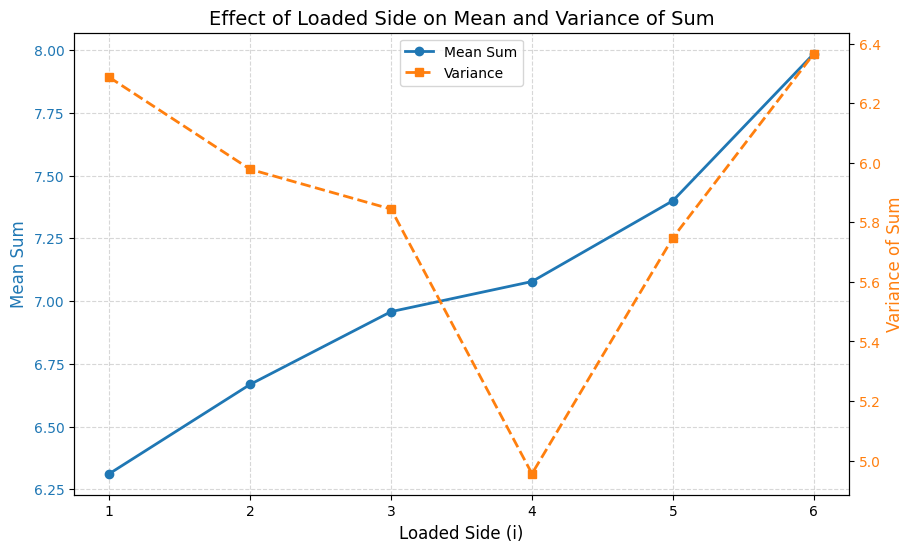

In [25]:
# Plotting the mean and variance of the loaded dice rolls to visualize the mathematical behavior
fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot Mean on primary y-axis
color = 'tab:blue'
ax1.set_xlabel('Loaded Side (i)', fontsize=12)
ax1.set_ylabel('Mean Sum', color=color, fontsize=12)
line1 = ax1.plot(df_rolls_corrected.index, df_rolls_corrected['mean'], color=color, marker='o', linewidth=2, label='Mean Sum')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

# Plot Variance on secondary y-axis
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Variance of Sum', color=color, fontsize=12)
line2 = ax2.plot(df_rolls_corrected.index, df_rolls_corrected['var'], color=color, marker='s', linewidth=2, linestyle='--', label='Variance')
ax2.tick_params(axis='y', labelcolor=color)

# Combine legends
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper center')

plt.title('Effect of Loaded Side on Mean and Variance of Sum', fontsize=14)
plt.show()